<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS04/datasetPBL/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Load kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Gabungkan kedua dataset melalui 'cafe_id'
df = pd.merge(
    df_reviews,
    df_cafes,
    on='cafe_id',
    how='left',
    suffixes=('_review', '_cafe')
)

df.head()

,review_id,cafe_id,author_name,rating_review,text,published_at,likes,scraped_at_review,name,address,latitude,longitude,rating_cafe,review_count,categories,phone,website,scraped_at_cafe,source_query
0,21314615-664d-438a-9f68-142f5b13f4c9,ba4b512c-fa2d-4959-8384-8570c81121ec,Alicia K. Taruli Manurung,5.0,Hore!,11 menit lalu,0,2026-10-11T13:54:49.423310,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
1,ec085c18-dced-4c23-8a65-4f71f93ed181,ba4b512c-fa2d-4959-8384-8570c81121ec,seobchwi fb,5.0,Pelayanan bagus dan ramah apalagi barista yg p...,14 menit lalu,0,2026-10-11T13:54:49.622536,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
2,6f1a2d5a-01c1-4fc9-8cfb-c4f5c8f58ec1,ba4b512c-fa2d-4959-8384-8570c81121ec,Nico Julianda,5.0,"comfort places for everything i did, mulai dar...",22 menit lalu,0,2026-10-11T13:54:49.854029,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
3,fd86734a-dcef-4f6d-8251-e47b203c0199,ba4b512c-fa2d-4959-8384-8570c81121ec,nazira parsa_04,5.0,"minumannya enak"", tempatnya comfy. worth to try",23 menit lalu,0,2026-10-11T13:54:49.967848,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang
4,cdeda318-e583-4473-9fd0-4e4b48b56e16,ba4b512c-fa2d-4959-8384-8570c81121ec,dulkamdi dul,5.0,"kopian 24jam enak banget kalau dibuat wfc, tem...",28 menit lalu,0,2026-10-11T13:54:50.058719,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang


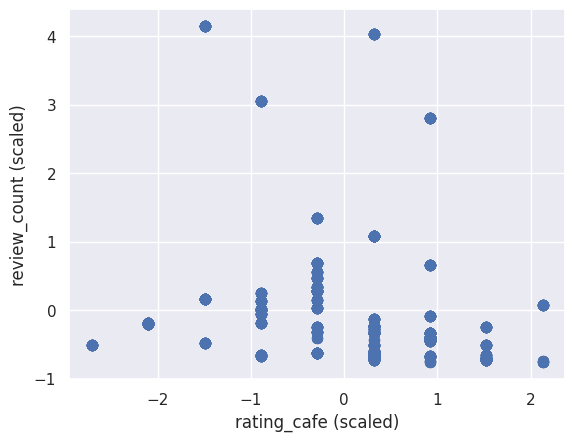

In [2]:
# Tentukan fitur yang tepat (minimal 2 fitur numerik)
X = df[['rating_cafe', 'review_count']].values

# Standardisasi skala fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=50)
plt.xlabel('rating_cafe (scaled)')
plt.ylabel('review_count (scaled)')
plt.show()

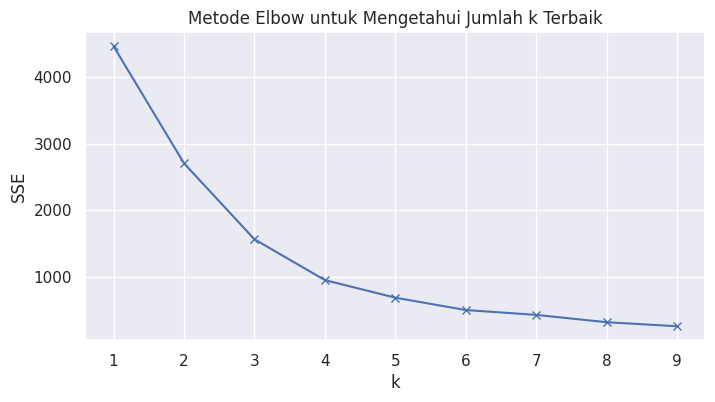

k=1; SSE=4460.000000000001
k=2; SSE=2705.4635046377502
k=3; SSE=1566.7259953281994
k=4; SSE=954.5493475365712
k=5; SSE=691.5538214145755
k=6; SSE=506.2591754183498
k=7; SSE=433.65736560548623
k=8; SSE=323.8355506651264
k=9; SSE=263.41200881890205


In [3]:
sse = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=0)
    kmeanModel.fit(X_scaled)
    sse.append(kmeanModel.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

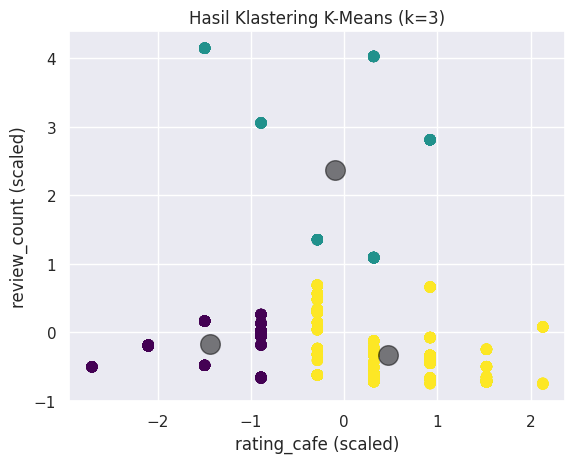

In [4]:
kmeans = KMeans(n_clusters=3, random_state=0)
y_kmeans = kmeans.fit_predict(X_scaled)

plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5)
plt.xlabel('rating_cafe (scaled)')
plt.ylabel('review_count (scaled)')
plt.title('Hasil Klastering K-Means (k=3)')
plt.show()